# From two levels to graphene multilayers with Pymablock

This tutorial has three parts.

1. **Warm-up:** the Pymablock workflow on a two-level system, where we know the exact answer.
2. **Bilayer graphene:** the k.p model of bilayer graphene derived from its tight-binding Hamiltonian, following the [Pymablock bilayer graphene tutorial](https://pymablock.readthedocs.io/en/latest/tutorial/bilayer_graphene.html).
3. **Extension:** the same calculation for three layers, where the quadratic bands of the bilayer become cubic.

In [ ]:
# Install Pymablock in the browser; numpy, scipy, sympy, and matplotlib come with Pyodide.
# This site serves a build of Pymablock's main branch, which solves sparse systems with
# SciPy when MUMPS is unavailable (as in the browser).
%pip install -q pymablock

In [ ]:
"""NM4QM tutorial: from two levels to graphene multilayers with Pymablock."""

from itertools import pairwise

import matplotlib.pyplot as plt
import numpy as np
import sympy
from sympy import Add, Eq, I, MatAdd, Matrix, exp, pi, sqrt, symbols
from sympy.physics.vector import ReferenceFrame

from pymablock import block_diagonalize


## Warm-up: a two-level system

Consider a state at energy $0$ coupled with strength $g$ to a state at energy $\Delta$:

$$
H = \begin{pmatrix} 0 & g \\ g & \Delta \end{pmatrix} = H_0 + g\, \sigma_x, \qquad H_0 = \begin{pmatrix} 0 & 0 \\ 0 & \Delta \end{pmatrix}.
$$

For $g \ll \Delta$ the lower level is shifted by the familiar second-order correction $-g^2/\Delta$.
Pymablock finds the unitary transformation that decouples the two states order by order in $g$.
We call the state we keep subspace $A$ and the state we eliminate subspace $B$.

Three pieces of input are needed:

- the Hamiltonian, here a SymPy matrix,
- the perturbative parameters, given as `symbols`,
- which basis states belong to which subspace. Because $H_0$ is already diagonal, `subspace_indices=[0, 1]` puts the first state in $A$ and the second in $B$.

In [ ]:
g, Delta = symbols("g Delta", positive=True)
H_two_level = Matrix([[0, g], [g, Delta]])

H_tilde, U, U_adjoint = block_diagonalize(
    H_two_level, symbols=[g], subspace_indices=[0, 1]
)

`block_diagonalize` returns the block-diagonalized Hamiltonian $\tilde{H}$, the unitary $U$, and its adjoint.
Nothing has been computed yet: we only compute the orders we ask for.
We index them as `H_tilde[block, block, order]`, where block `0` is $A$ and block `1` is $B$.

In [ ]:
H_tilde[0, 0, 2]

Several orders can be requested at once with a slice.
Orders that vanish identically are masked, here all the odd ones.

In [ ]:
H_tilde[0, 0, :7]

In [ ]:
E_pymablock = Add(*H_tilde[0, 0, :7].compressed())[0, 0]
E_pymablock

We compare with the exact lower eigenvalue $E_- = \left(\Delta - \sqrt{\Delta^2 + 4g^2}\right)/2$:

In [ ]:
E_minus = (Delta - sqrt(Delta**2 + 4 * g**2)) / 2
sympy.simplify(sympy.series(E_minus, g, 0, 7).removeO())

The unitary tells us how the new states are built from the old ones:

In [ ]:
U[1, 0, 1]

That is the whole workflow: define $H$, choose the subspaces, and query the orders you need.
In graphene the unperturbed Hamiltonian will not be diagonal, so instead of `subspace_indices` we will pass its eigenvectors with `subspace_eigenvectors`.

## Bilayer graphene

We now construct the k.p Hamiltonian of bilayer graphene, starting from its tight-binding dispersion.

The crystal structure and the hoppings of bilayer graphene are:

![Bilayer graphene. Top view: the unit cell spanned by a_1 and a_2 contains the sites φ_{A,1}, φ_{B,1}, φ_{A,2}, φ_{B,2}, with intralayer hopping t_1 and interlayer hopping t_2 between φ_{B,1} and φ_{A,2}. Side view: the gates set a displacement field D, which puts the layers at potential energies +D and -D; the dashed circles mark the low-energy sites φ_{A,1} and φ_{B,2}.](attachment:bilayer.png)

Main features:

- Unit cell vectors $\mathbf{a}_1=(1/2, \sqrt{3}/2)$ and $\mathbf{a}_2=(-1/2, \sqrt{3}/2)$.
- 4 atoms per cell with wave functions $\phi_{A,1}, \phi_{B,1}, \phi_{A,2}, \phi_{B,2}$.
- Hoppings within each layer are $t_1$.
- Interlayer hopping couples atoms that are on top of each other, $t_2$.
- An electric field set by the displacement field $D$ between a top and a bottom gate puts the two layers at different potentials.

If you want to get a more systematic introduction to the bilayer graphene and its k.p model, you can check out [this review](https://iopscience.iop.org/article/10.1088/0034-4885/76/5/056503).

### Define a symbolic Hamiltonian

Now we are ready to define all the parameters and the Hamiltonian $H$.
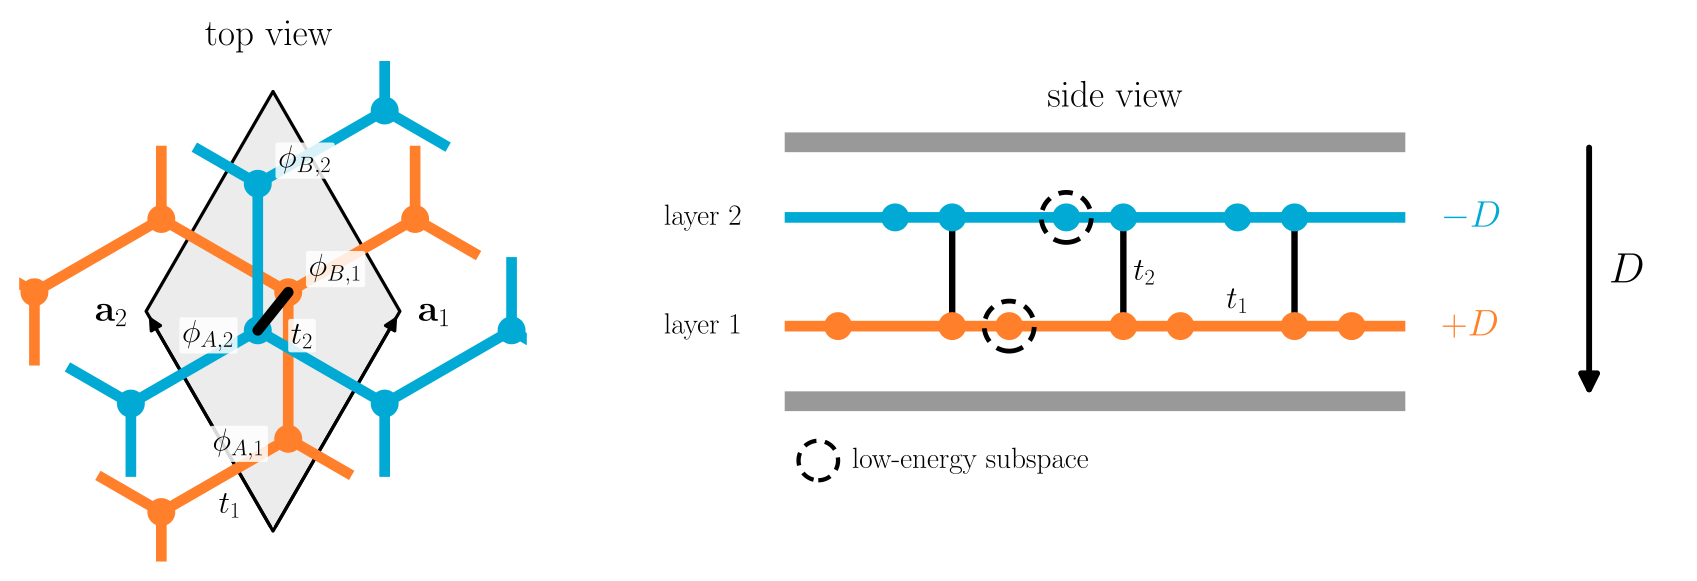

In [ ]:
k_x, k_y, t_1, t_2, D = symbols("k_x k_y t_1 t_2 D", real=True)
alpha = symbols(r"\alpha")

H = Matrix(
    [
        [D, t_1 * alpha, 0, 0],  # A1
        [t_1 * alpha.conjugate(), D, t_2, 0],  # B1
        [0, t_2, -D, t_1 * alpha],  # A2
        [0, 0, t_1 * alpha.conjugate(), -D],  # B2
    ]
)
Eq(symbols("H"), H, evaluate=False)

We collected all momentum-dependent factors into the symbol $\alpha$.

We also make $\mathbf{K}=(4\pi/3, 0)$ the reference point for the $\mathbf{k}$-vector, making $k_x$ and $k_y$ the perturbative parameters.

In [ ]:
N = ReferenceFrame("N")
a_1 = (sqrt(3) * N.y + N.x) / 2
a_2 = (sqrt(3) * N.y - N.x) / 2
k = (4 * pi / 3 + k_x) * N.x + k_y * N.y

alpha_k = (1 + exp(I * k.dot(a_1)) + exp(I * k.dot(a_2))).expand(complex=True, trig=True)
Eq(alpha, alpha_k, evaluate=False)

### Band structure

Before doing any perturbation theory, let's see the bands!
The function `plot_bands(H_k, parameters, n_low, title)` below diagonalizes the tight-binding Hamiltonian.
The plot highlights the `n_low` low-energy bands that the effective model will describe near $K$.

In [ ]:
K_point = np.array([4 * np.pi / 3, 0])
M_point = np.pi * np.array([1, 1 / np.sqrt(3)])
Gamma_point = np.zeros(2)


def plot_bands(H_k, parameters, n_low, title):
    """Bands of H_k (a function of k measured from K) along Γ-K-M-Γ and near K.

    `parameters` maps the model symbols other than k_x and k_y to numbers.
    """
    H_numeric = sympy.lambdify((k_x, k_y), H_k.subs(parameters), "numpy")

    def bands(k_points):
        return np.array(
            [np.linalg.eigvalsh(np.array(H_numeric(*k), dtype=complex)) for k in k_points]
        )

    corners = [Gamma_point, K_point, M_point, Gamma_point]
    path = np.concatenate(
        [np.linspace(start, end, 100, endpoint=False) for start, end in pairwise(corners)]
        + [corners[-1][None]]
    )
    distance = np.concatenate(
        [[0], np.cumsum(np.linalg.norm(np.diff(path, axis=0), axis=1))]
    )
    energies = bands(path - K_point)

    zoom_k = np.linspace(-0.15, 0.15, 201)
    zoom_energies = bands(np.stack([zoom_k, np.zeros_like(zoom_k)], axis=1))

    n_bands = energies.shape[1]
    low = np.arange(n_bands // 2 - n_low // 2, n_bands // 2 + n_low // 2)
    high = np.setdiff1d(np.arange(n_bands), low)

    fig, (ax_full, ax_zoom) = plt.subplots(
        1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [3, 2]}
    )
    for ax, x, E in ((ax_full, distance, energies), (ax_zoom, zoom_k, zoom_energies)):
        ax.plot(x, E[:, high], color="0.6", lw=1.5)
        ax.plot(x, E[:, low], color="C1", lw=2.5)
        ax.set_ylabel("$E$ (eV)")
    ax_full.plot([], [], color="C1", lw=2.5, label="low-energy bands (kept)")
    ax_full.plot([], [], color="0.6", lw=1.5, label="split-off bands (eliminated)")
    ax_full.legend(loc="upper center", fontsize=10, framealpha=1)
    ticks = distance[[0, 100, 200, 300]]
    ax_full.set_xticks(ticks, [r"$\Gamma$", "$K$", "$M$", r"$\Gamma$"])
    for tick in ticks:
        ax_full.axvline(tick, color="0.85", lw=0.8, zorder=0)
    ax_full.set_xlim(ticks[0], ticks[-1])
    ax_full.set_title(title)
    ax_zoom.set_xlim(zoom_k[0], zoom_k[-1])
    ax_zoom.set_ylim(-0.6, 0.6)
    # Separation between the kept bands and the nearest eliminated bands at K.
    center = len(zoom_k) // 2
    kept_top, eliminated_above = zoom_energies[center, [low[-1], low[-1] + 1]]
    ax_zoom.annotate(
        "",
        (0.02, eliminated_above),
        (0.02, kept_top),
        arrowprops=dict(arrowstyle="<|-|>", color="C0", shrinkA=0, shrinkB=0),
    )
    ax_zoom.text(
        0.03,
        (kept_top + eliminated_above) / 2,
        f"{1e3 * (eliminated_above - kept_top):.0f} meV",
        color="C0",
        va="center",
        fontsize=10,
    )
    ax_zoom.set_xlabel(r"$k_x$ near $K$ (inverse lattice constants)")
    ax_zoom.set_title("near $K$")
    # Fixed spacing instead of tight_layout, which warns in the JupyterLite backend.
    fig.subplots_adjust(left=0.07, right=0.98, bottom=0.16, top=0.91, wspace=0.22)

We substitute realistic hoppings $t_1 = 3\ \mathrm{eV}$ and $t_2 = 0.4\ \mathrm{eV}$, and a layer potential $D = 20\ \mathrm{meV}$ that is large enough to see.
The dictionary `parameters` maps each symbol to its numerical value; we reuse it for all numerical checks below.

In [ ]:
parameters = {t_1: 3.0, t_2: 0.4, D: 0.02}

In [ ]:
plot_bands(H.subs({alpha: alpha_k}), parameters, n_low=2, title="bilayer graphene")

The two highlighted bands live on the sites $\phi_{A,1}$ and $\phi_{B,2}$; near $K$ they disperse quadratically and are separated by the gap $2D$.
Close to $K$, these are the bands we now describe with an effective $2\times2$ Hamiltonian.

### Define the perturbative series

At $\mathbf{k} = \mathbf{K}$ and $D = 0$ the unperturbed Hamiltonian couples only the two dimer sites $\phi_{B,1}$ and $\phi_{A,2}$, so it is not diagonal.
We obtain its eigenvectors by setting $\alpha = 0$ and $D = 0$ (`subs`) and diagonalizing (`diagonalize`).

In [ ]:
vecs, vals = H.subs({alpha: 0, D: 0}).diagonalize(normalize=True)

In [ ]:
vals

In [ ]:
vecs

The first two eigenvectors are the zero-energy states on the non-dimer sites $\phi_{A,1}$ and $\phi_{B,2}$; they form subspace $A$.
The other two are the ones we want to eliminate.

We substitute full expression for $\alpha(k)$ into the Hamiltonian and we `block_diagonalize` it.
For that we specify which symbols are the perturbative parameters using the `symbols` argument.
The order of `symbols` is important: it defines the order of variables in the perturbative series.

In [ ]:
H_tilde = block_diagonalize(
    H.subs({alpha: alpha_k}),
    symbols=(k_x, k_y, D),
    subspace_eigenvectors=[vecs[:, :2], vecs[:, 2:]],
)[0]

The names of `symbols` specifying the perturbative parameters are stored in the `dimension_names` attribute of the result:

In [ ]:
H_tilde.dimension_names

> **All symbols are commutative.**
> Pymablock treats all `symbols` as commutative by default.
> To use non-commutative symbols, like e.g. $x$ and $k_x$, add these into the Hamiltonian directly instead.

Now we are ready to specify which calculation to perform.
`H_tilde` now has three perturbative indices, so `H_tilde[0, 0, i, j, l]` is the term of order $k_x^i k_y^j D^l$.

To compute the standard quadratic dispersion of bilayer graphene and trigonal warping, we need corrections up to third order in momentum.
Let us then group the terms by total power of momentum.
We select all pairs of powers $(i, j)$ of $(k_x, k_y)$ with a given total $i + j$ using `np.mgrid`:

In [ ]:
k_powers = np.mgrid[:4, :4]
k_square = k_powers[..., np.sum(k_powers, axis=0) == 2]
k_cube = k_powers[..., np.sum(k_powers, axis=0) == 3]
k_square

To gather different entries into one symbolic expression, we define a convenience function that sums several orders together.
This uses the `compressed` method of masked numpy arrays, and simplifies the resulting expression.

In [ ]:
def H_tilde_AA(*orders):
    """Sum and simplify the terms of the bilayer H_tilde_AA with the given orders."""
    return Add(*H_tilde[0, 0, orders[0], orders[1], orders[2]].compressed()).simplify()

Finally, we are ready to obtain the result.

In [ ]:
%%time

field_term = H_tilde_AA([0], [0], [1])
kinetic = H_tilde_AA(*k_square, 0)
field_correction = H_tilde_AA(*k_square, 1)
cubic = H_tilde_AA(*k_cube, 0)
MatAdd(field_term + kinetic, field_correction + cubic, evaluate=False)

The first term contains the standard quadratic dispersion of bilayer graphene with a gap.
The second term contains trigonal warping and the coupling between the gap and momentum.

## Extension: rhombohedral (ABC) trilayer graphene

We now add a third shifted layer on top of the bilayer.
The displacement field now drops linearly across three equally spaced layers, so their potential energies are $+D$, $0$, and $-D$.

![ABC trilayer graphene. Top view: each layer is shifted by one bond length relative to the layer below, so φ_{B,1} sits below φ_{A,2} and φ_{B,2} below φ_{A,3}; these pairs are coupled by t_2. Side view: the displacement field D puts the layers at +D, 0, and -D; the outer sites φ_{A,1} and φ_{B,3} have no interlayer partner and form the low-energy subspace.](attachment:rhombohedral.png)

The Hamiltonian follows the same pattern as before, with the basis $(\phi_{A,1}, \phi_{B,1}, \phi_{A,2}, \phi_{B,2}, \phi_{A,3}, \phi_{B,3})$.
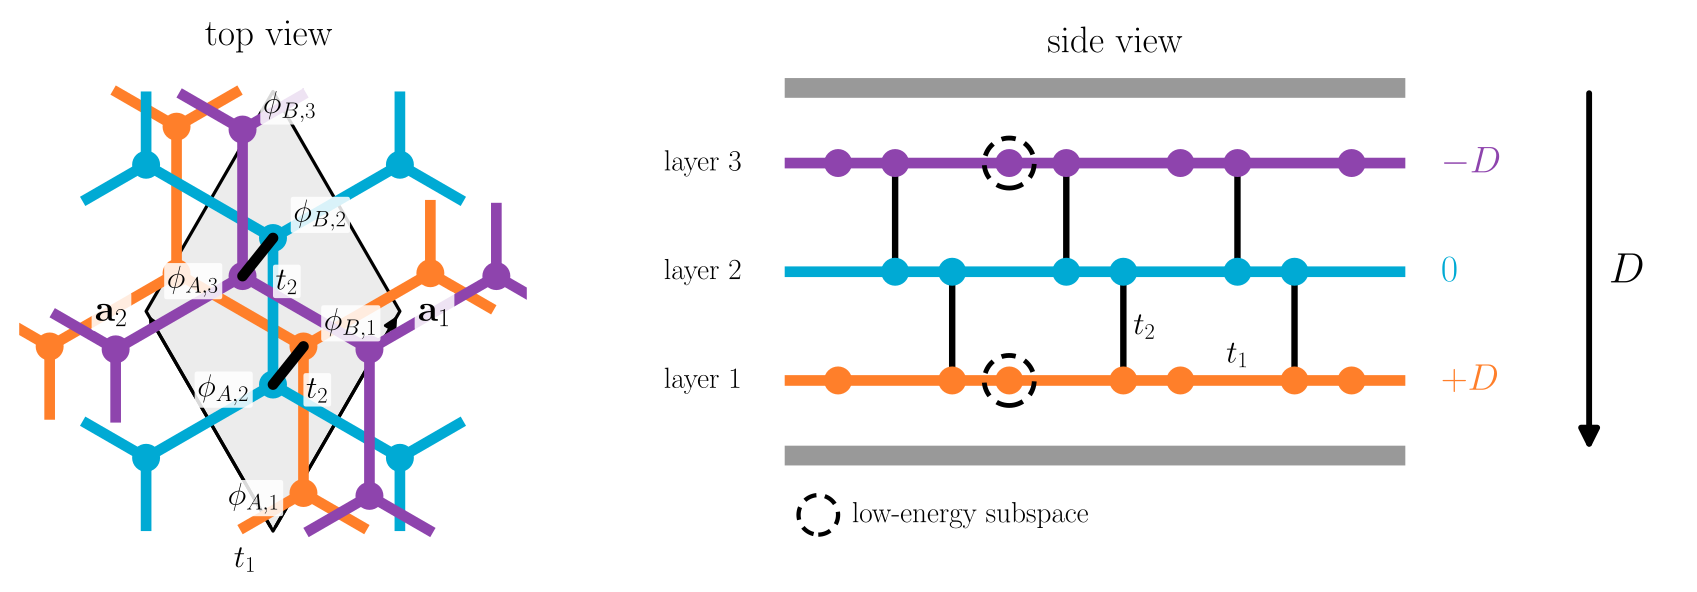

In [ ]:
H_3 = Matrix(
    [
        [D, t_1 * alpha, 0, 0, 0, 0],  # A1
        [t_1 * alpha.conjugate(), D, t_2, 0, 0, 0],  # B1
        [0, t_2, 0, t_1 * alpha, 0, 0],  # A2
        [0, 0, t_1 * alpha.conjugate(), 0, t_2, 0],  # B2
        [0, 0, 0, t_2, -D, t_1 * alpha],  # A3
        [0, 0, 0, 0, t_1 * alpha.conjugate(), -D],  # B3
    ]
)
Eq(symbols("H_3"), H_3, evaluate=False)

With the same parameters as for the bilayer, the trilayer has six bands.

In [ ]:
plot_bands(H_3.subs({alpha: alpha_k}), parameters, n_low=2, title="ABC trilayer graphene")

Again we diagonalize the unperturbed Hamiltonian.
SymPy does not promise any order of the eigenvectors, so we select the zero-energy ones explicitly instead of relying on their position.

In [ ]:
eigenvectors, eigenvalues = H_3.subs({alpha: 0, D: 0}).diagonalize(normalize=True)
low_energy = [i for i in range(6) if eigenvalues[i, i] == 0]
high_energy = [i for i in range(6) if eigenvalues[i, i] != 0]
vecs_3 = eigenvectors[:, low_energy + high_energy]
vecs_3

The first two columns are $\phi_{A,1}$ and $\phi_{B,3}$, as expected.
The rest of the calculation is identical to the bilayer.

In [ ]:
H_tilde_3 = block_diagonalize(
    H_3.subs({alpha: alpha_k}),
    symbols=(k_x, k_y, D),
    subspace_eigenvectors=[vecs_3[:, :2], vecs_3[:, 2:]],
)[0]


def H_tilde_3_AA(*orders):
    """Sum and simplify the terms of the trilayer H_tilde_AA with the given orders."""
    return Add(*H_tilde_3[0, 0, orders[0], orders[1], orders[2]].compressed()).simplify()

We collect the terms by total power of momentum, now up to $k^3$.

In [ ]:
%%time

k_linear = k_powers[..., np.sum(k_powers, axis=0) == 1]
field_term_3 = H_tilde_3_AA([0], [0], [1])
linear_3 = H_tilde_3_AA(*k_linear, 0)
quadratic_3 = H_tilde_3_AA(*k_square, 0)
cubic_3 = H_tilde_3_AA(*k_cube, 0)
field_correction_3 = H_tilde_3_AA(*k_square, 1)
print("terms linear and quadratic in k:", linear_3, quadratic_3)
MatAdd(field_term_3 + cubic_3, field_correction_3, evaluate=False)

The linear and quadratic terms vanish, and the leading dispersion is cubic.
Factoring the off-diagonal element makes its structure clear:

In [ ]:
sympy.factor(cubic_3[0, 1])


### Checking against the full trilayer Hamiltonian

Finally we compare the effective model with the exact bands of the $6 \times 6$ Hamiltonian.

In [ ]:
H_3_exact = sympy.lambdify(
    (k_x, k_y), H_3.subs({alpha: alpha_k}).subs(parameters), "numpy"
)
H_3_effective = sympy.lambdify(
    (k_x, k_y), (field_term_3 + cubic_3 + field_correction_3).subs(parameters), "numpy"
)

k_scan = np.linspace(-0.08, 0.08, 201)
exact_bands = np.array(
    [np.linalg.eigvalsh(np.array(H_3_exact(k, 0), dtype=complex)) for k in k_scan]
)
effective_bands = np.array(
    [np.linalg.eigvalsh(np.array(H_3_effective(k, 0), dtype=complex)) for k in k_scan]
)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(k_scan, exact_bands[:, 2:4], color="k", lw=3, label=["exact $6\\times6$", None])
ax.plot(
    k_scan,
    effective_bands,
    "--",
    color="C1",
    lw=2,
    label=["effective $2\\times2$", None],
)
ax.set_ylim(-0.1, 0.1)
ax.set_xlabel(r"$k_x$ (inverse lattice constants)")
ax.set_ylabel("$E$ (eV)")
ax.legend()

The effective Hamiltonian reproduces the flat, cubic low-energy bands and the gap $2D$ at small momentum.
It deviates once $\hbar v k$ becomes comparable to $t_2$, where higher orders in $k$ become important.

**Try it yourself:**

- Add a fourth layer. Which power of $k$ do you expect, and how does the prefactor scale with $t_2$?
- In Bernal (ABA) trilayer graphene the third layer sits directly above the first. Change $H_3$ accordingly and see which parts of the monolayer and bilayer physics you recover.

The [bilayer graphene quantum dot tutorial](/contents/demos/nm4qm-17-10-2026/notebooks/index.html?path=bilayer_dot.ipynb) continues with a numerical problem: a gated dot with 32,400 orbitals, which needs Pymablock's implicit method.